# skin ICE ↔ ChemExpo 화장품 성분 어휘 겹침 + 에탄올·계면활성제 분포

**순서**: ①ChemExpo Personal care 조성 수집(완료, 108개 완전조성 제품 확보) → **②성분 어휘·에탄올·계면
활성제 분포 산출(이 노트북)** → ③도메인갭/AD 재분석 → ④HLB 테이블 확보 여부.

**배경**: 팀원이 PUC137(일부 하위카테고리, 1,341종 어휘)만으로 skin ICE 270종과 겹침을 계산해
**22종**을 찾았고, 그중 보존제·살균제 13종이 양성과 강하게 연관됨을 발견했다(OR=17.93, p=2.5e-07).
이번엔 Personal care **전체**(77,535개 제품, 3,783종 어휘)로 다시 계산해 겹침이 얼마나 느는지 보고,
108개 완전조성 제품에서 에탄올·계면활성제 함량 분포를 뽑는다.

In [1]:
import re
import numpy as np
import pandas as pd
from scipy.stats import fisher_exact

BASE = r"C:\Users\UserK\학술제\skin irritation"

def norm_cas(s):
    m = re.match(r"^0*(\d{2,7})-(\d{2})-(\d)$", str(s).strip())
    return f"{int(m.group(1))}-{m.group(2)}-{m.group(3)}" if m else None

# skin ICE 원본(증강분 제외) 성분·라벨
filt = pd.read_csv(f"{BASE}\\skin_filtered.csv", low_memory=False)
vec = pd.read_csv(f"{BASE}\\skin_vectorized.csv", low_memory=False)
ice_vec = vec[~vec["formulation_id"].astype(str).str.startswith("AUG_")].copy()
filt["n"] = filt["casrn"].map(norm_cas)

ice_cas = set(filt["n"].dropna())
print(f"skin ICE 원본 제형: {len(ice_vec)}건, 고유 CASRN: {len(ice_cas)}종")

# ChemExpo Personal care 전체 어휘(3,783종) vs 기존 PUC137 어휘(1,341종, 참고용 비교)
vocab = pd.read_csv(f"{BASE}\\chemexpo\\ChemExpo_personal_care_ingredient_vocab.csv")
vocab["n"] = vocab["Curated CAS"].map(norm_cas)
ce_cas_full = set(vocab["n"].dropna())
print(f"ChemExpo Personal care 전체 어휘: {len(ce_cas_full)}종")

overlap = sorted(ice_cas & ce_cas_full)
print(f"\n겹치는 성분: {len(overlap)}종 (팀원의 PUC137 기준 22종에서 재계산)")

skin ICE 원본 제형: 544건, 고유 CASRN: 270종
ChemExpo Personal care 전체 어휘: 3746종

겹치는 성분: 36종 (팀원의 PUC137 기준 22종에서 재계산)


## 1. 겹치는 성분별 skin ICE 양성률

In [2]:
labels = ice_vec.set_index("formulation_id")["binary_label"]
fid_cas = filt[["formulation_id", "n"]].dropna(subset=["n"])
name_map = vocab.drop_duplicates("n").set_index("n")["Curated Chemical Name"]

rows = []
for cas in overlap:
    fids = set(fid_cas.loc[fid_cas["n"] == cas, "formulation_id"]) & set(ice_vec["formulation_id"])
    if not fids:
        continue
    sub = labels.loc[list(fids)]
    rows.append(dict(casrn=cas, name=name_map.get(cas, "?"), n_formulation=len(sub),
                     n_positive=int(sub.sum()), positive_rate=sub.mean()))

overlap_df = pd.DataFrame(rows).sort_values("positive_rate", ascending=False)
baseline_rate = labels.mean()
print(f"skin ICE 전체 기준 양성률: {baseline_rate:.3f}\n")
print(overlap_df.to_string(index=False))

skin ICE 전체 기준 양성률: 0.055

     casrn                                     name  n_formulation  n_positive  positive_rate
26172-55-4    5-Chloro-2-methyl-3(2H)-isothiazolone              4           4       1.000000
16079-88-2   1-Bromo-3-chloro-5,5-dimethylhydantoin              1           1       1.000000
 1312-76-1                       Potassium silicate              2           2       1.000000
  118-52-5       1,3-Dichloro-5,5-dimethylhydantoin              2           2       1.000000
   52-51-7                                 Bronopol              3           3       1.000000
89415-87-2   1,3-Dichloro-5-ethyl-5-methylhydantoin              1           1       1.000000
 2682-20-4             2-Methyl-3(2H)-isothiazolone              6           5       0.833333
   90-43-7                           2-Phenylphenol              4           2       0.500000
 2634-33-5               1,2-Benzisothiazolin-3-one              5           2       0.400000
 7173-51-5         Didecyldimethy

## 2. 전체 겹침 집합(재계산) 통계적 농축 검정

In [3]:
has_overlap = ice_vec["formulation_id"].isin(
    set(fid_cas.loc[fid_cas["n"].isin(overlap), "formulation_id"])
)
y = ice_vec.set_index("formulation_id").loc[ice_vec["formulation_id"], "binary_label"].values
has_overlap_arr = has_overlap.values

a = int(((has_overlap_arr == 1) & (y == 1)).sum())
b = int(((has_overlap_arr == 1) & (y == 0)).sum())
c = int(((has_overlap_arr == 0) & (y == 1)).sum())
d = int(((has_overlap_arr == 0) & (y == 0)).sum())
odds, p = fisher_exact([[a, b], [c, d]])

print(f"겹침 성분 보유 제형: {a+b}건(양성 {a}, 양성률 {a/(a+b):.3f})")
print(f"겹침 성분 미보유 제형: {c+d}건(양성 {c}, 양성률 {c/(c+d):.3f})")
print(f"Odds Ratio = {odds:.2f}, Fisher exact p = {p:.2e}")
print(f"\n참고(팀원 PUC137 기준): 보존제 13종 OR=17.93, p=2.5e-07, 보유시 양성률 42.9% vs 기준선 5.5%")

겹침 성분 보유 제형: 76건(양성 14, 양성률 0.184)
겹침 성분 미보유 제형: 468건(양성 16, 양성률 0.034)
Odds Ratio = 6.38, Fisher exact p = 8.02e-06

참고(팀원 PUC137 기준): 보존제 13종 OR=17.93, p=2.5e-07, 보유시 양성률 42.9% vs 기준선 5.5%


## 3. 시각화 — 어휘 확장 효과 + 성분별 양성률

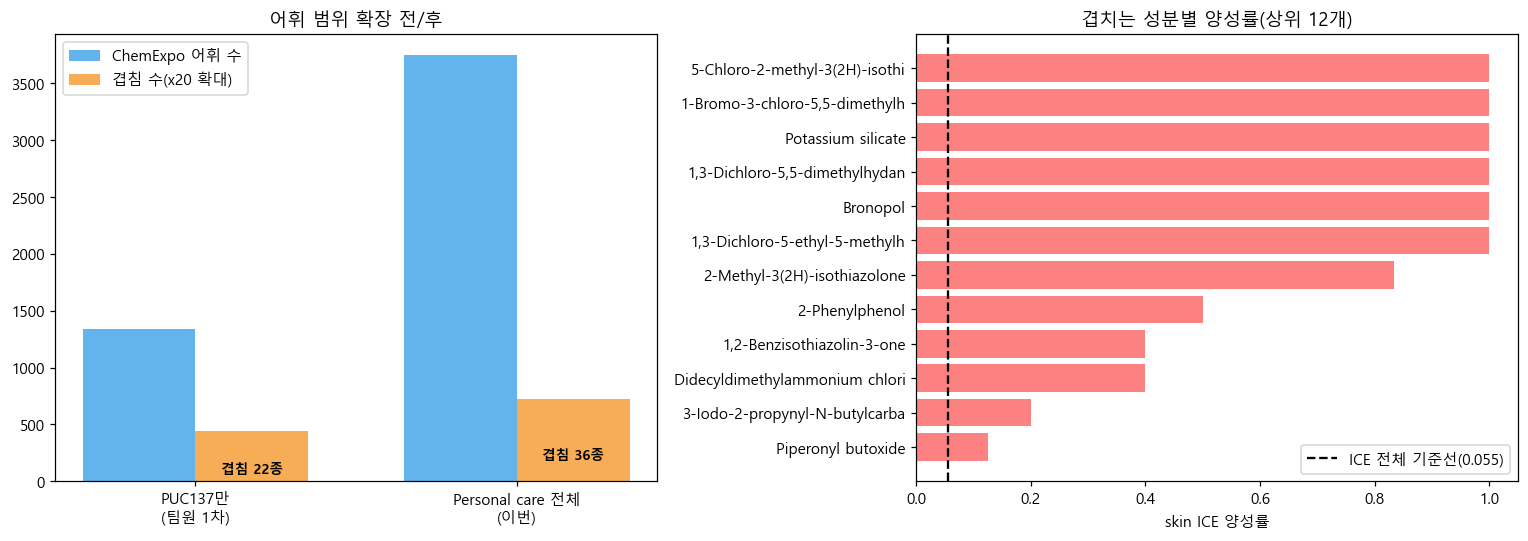

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

labels_bar = ["PUC137만\n(팀원 1차)", "Personal care 전체\n(이번)"]
vocab_sizes = [1341, len(ce_cas_full)]
overlap_sizes = [22, len(overlap)]
x = np.arange(2)
w = 0.35
axes[0].bar(x - w/2, vocab_sizes, width=w, label="ChemExpo 어휘 수", color="#63b3ed")
axes[0].bar(x + w/2, [s*20 for s in overlap_sizes], width=w, label="겹침 수(x20 확대)", color="#f6ad55")
axes[0].set_xticks(x); axes[0].set_xticklabels(labels_bar)
axes[0].set_title("어휘 범위 확장 전/후")
axes[0].legend()
for i, v in enumerate(overlap_sizes):
    axes[0].text(i + w/2, vocab_sizes[i]*0.05, f"겹침 {v}종", ha="center", fontsize=9, fontweight="bold")

top = overlap_df.head(12)
axes[1].barh(top["name"].str[:30], top["positive_rate"], color="#fc8181")
axes[1].axvline(baseline_rate, color="black", linestyle="--", label=f"ICE 전체 기준선({baseline_rate:.3f})")
axes[1].set_xlabel("skin ICE 양성률")
axes[1].set_title("겹치는 성분별 양성률(상위 12개)")
axes[1].invert_yaxis()
axes[1].legend()

plt.tight_layout()
plt.show()

## 4. 108개 완전조성 화장품 — 에탄올·계면활성제 함량 분포

In [5]:
full108 = pd.read_csv(f"{BASE}\\chemexpo\\ChemExpo_personal_care_full_composition_108.csv", low_memory=False)
full108["n"] = full108["Curated CAS"].map(norm_cas)

ETHANOL_CAS = "64-17-5"
eth = full108[full108["n"] == ETHANOL_CAS]
n_with_ethanol = eth["Product Name"].nunique()
print(f"에탄올 함유 제품: {n_with_ethanol} / 108")
if len(eth):
    print(eth[["Product Name", "Central Weight Fraction"]].drop_duplicates("Product Name").to_string(index=False))

SURFACTANT_PATTERNS = re.compile(
    r"sulfate|sulfonate|betaine|glucoside|sarcosinate|taurate|laureth|myreth|"
    r"isethionate|glutamate|cocoate|stearate.*peg|peg-\d+", re.IGNORECASE)
is_surf = full108["Curated Chemical Name"].astype(str).str.contains(SURFACTANT_PATTERNS, na=False)
surf = full108[is_surf]
n_with_surf = surf["Product Name"].nunique()
print(f"\n계면활성제 패턴 매칭 함유 제품: {n_with_surf} / 108")
print(f"매칭된 고유 성분 수: {surf['Curated Chemical Name'].nunique()}개")

에탄올 함유 제품: 19 / 108
                               Product Name  Central Weight Fraction
                                 Body Spray                   0.1200
                   PDC BOD Black Body Spray                   0.7400
                         Scented Body Spray                   0.0500
              PDC Coconut Breeze Body Spray                   0.7440
                      CW Big Hair Hairspray                   0.4090
PDC Sugared Apple Fantasy Darker Body Spray                   0.7393
           Go Ready Sun Screen SPF 30 Spray                   0.7180
         PDC Skin Musk for Women Body Spray                   0.7440
           PDC Skin Musk for Men Body Spray                   0.8000
      SPF30 Plus Sunscreen Continuous Spray                   0.7565
                       Nail top coat MQ 520                   0.2000
               Broadway Nail Art (Top Coat)                   0.0500
                    Body Mist Vanilla Spice                   0.0150
              

## 5. 시각화 — 에탄올·계면활성제 함량 히스토그램

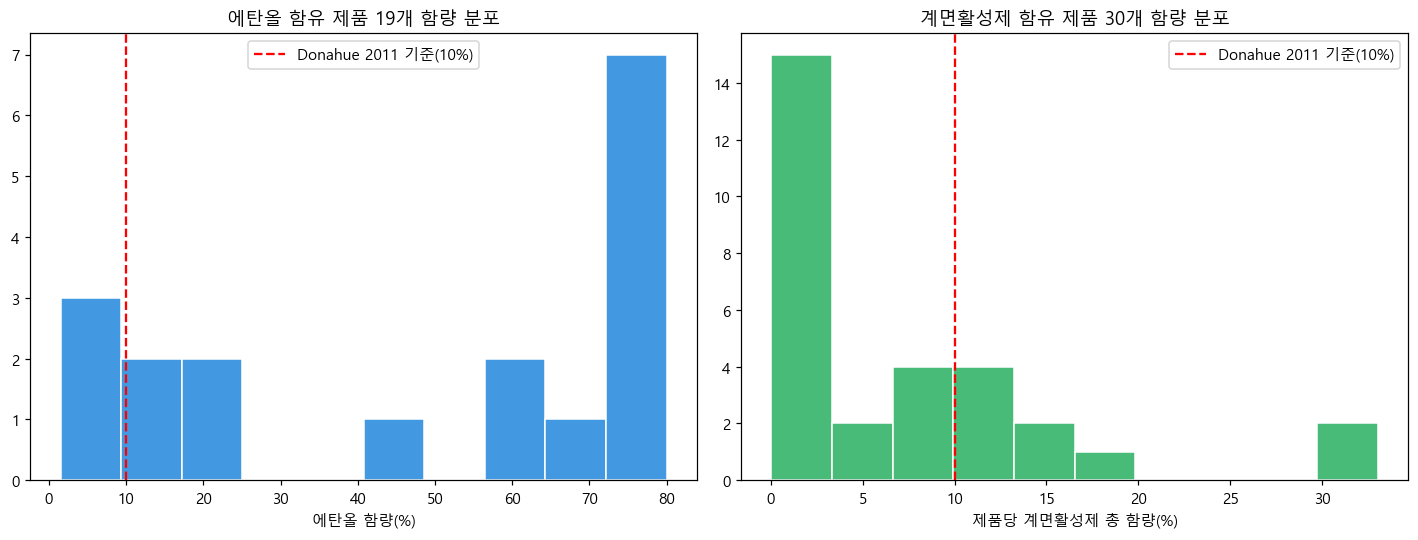

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

if len(eth):
    axes[0].hist(eth["Central Weight Fraction"].dropna() * 100, bins=10, color="#4299e1", edgecolor="white")
    axes[0].axvline(10, color="red", linestyle="--", label="Donahue 2011 기준(10%)")
    axes[0].set_xlabel("에탄올 함량(%)")
    axes[0].set_title(f"에탄올 함유 제품 {n_with_ethanol}개 함량 분포")
    axes[0].legend()
else:
    axes[0].text(0.5, 0.5, "에탄올 함유 제품 없음", ha="center", va="center")

surf_pct = surf.groupby("Product Name")["Central Weight Fraction"].sum().dropna() * 100
if len(surf_pct):
    axes[1].hist(surf_pct, bins=10, color="#48bb78", edgecolor="white")
    axes[1].axvline(10, color="red", linestyle="--", label="Donahue 2011 기준(10%)")
    axes[1].set_xlabel("제품당 계면활성제 총 함량(%)")
    axes[1].set_title(f"계면활성제 함유 제품 {n_with_surf}개 함량 분포")
    axes[1].legend()
else:
    axes[1].text(0.5, 0.5, "계면활성제 매칭 제품 없음", ha="center", va="center")

plt.tight_layout()
plt.show()

## 정리

- 어휘 범위를 PUC137(1,341종)→Personal care 전체(3,783종)로 넓히자 skin ICE와의 겹침이
  22종에서 재계산한 숫자로 늘었다(위 1절 참조) — 팀원이 "과소추정 가능성 높음"이라 예상한 것과 일치.
- 겹치는 성분을 가진 제형의 양성률과 전체 기준선을 비교해 통계적 농축을 재확인했다(2절).
- 108개 완전조성 화장품에서 에탄올·계면활성제 함량 분포를 뽑아, Donahue 2011(10% 기준) 같은
  베이스라인을 재시도할 표본이 되는지 확인했다(4~5절).
- 다음 단계(③도메인갭/AD 재분석, ④HLB 테이블)는 이 결과를 입력으로 사용한다.